# Assignment

Due: Tuesday, 3 November 2026, 1:00 PM
Problem description

Consider a picture representing a white sheet of A4 paper with some handwritten numbers in a dark color (they have different sizes, but they are all oriented in the same direction, which is aligned with one of the edges of the paper).  Consider the attached pictures as examples. Some are easy, others are harder. Note that the paper might be pictured at an angle or from a slanted perspective.  In all pictures the four edges of the paper are clearly visible, but might be incomplete.

Write a notebook that, given a directory, will process all images in that directory and extract all digits it can find from each picture. For each file, it should then print:

- the name of the file, followed by
- each of the digits that has been identified on that sheet of paper, from top to bottom.

## Suggested approach

One possible approach is the following:

- Load the image and resize it to a manageable size. You may want to convert it to grayscale.
- Look for edges using the Canny edge detector.
- Look for four long straight lines using the Hough line detector.
- The intersections between pairs of these lines should correspond to the corners of the paper sheet. (note: 4 lines define 6 different intersections!)
- Once you have the four corners of the sheet, you can obtain a straightened version of your sheet of paper, by a geometric transformation.
- Binarize and find connected components (this might be tricky when illumination is uneven. How to fix that?).
- Cut a square bounding box around each connected component.
- Resize that to a 28x28 and classify it using a convnet trained on the MNIST dataset.

## Some useful functions

To resize an image:

```python
skimage.transform.resize(image, output_shape)
```

The notebooks in this section help in finding the intersection point of two lines, and rectifying the image of sheet of paper.

To download a large dataset of handwritten digits, which can be used to train a classifier:

```python
from keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()
```

## Rules and expectations

The task is difficult and comprises several sub-tasks. You are not expected to implement a solution that works always perfectly.

The main goal is to implement a simple straightforward solution for each sub-task, then identify and discuss its weaknesses. When does it work? When does it fail? How could we make it better?

A forum is created on moodle to freely discuss these issues, brainstorm improvements, and exchange ideas about their implementation; the instructor takes part in the discussion and can provide suggestions.

## Submission and grading

Submit through moodle an HTML or PDF file of your notebook implementing your solution and describing your approach. Before saving, reset the kernel and run the entire notebook. Use markdown cells to describe what your code does, and illustrate intermediate results.

The final exam will contain a few questions that ask to describe how you implemented specific parts of the homework in your submitted solution. These will be graded and checked with the submitted solution; therefore, it is strongly suggested that students attempt to solve the homework and submit a solution before the deadline, even if incomplete.


# Solution

In [1]:
import collections
import keras
import skimage
import skimage.feature
import skimage.transform
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os
import random

from itertools import permutations, combinations
from keras import layers
from pathlib import Path
from scipy.spatial import ConvexHull, QhullError

I0000 00:00:1793665775.148294  990395 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793665775.148652  990395 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793665775.182770  990395 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793665776.131500  990395 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

## Load image and convert to grayscale

('Original:', <class 'numpy.ndarray'>, (4032, 3024, 3), dtype('uint8'), np.uint8(0), np.uint8(224))
('Gray:', <class 'numpy.ndarray'>, (4032, 3024), dtype('uint8'), np.uint8(2), np.uint8(210))
('Resized:', <class 'numpy.ndarray'>, (683, 512), dtype('uint8'), np.uint8(8), np.uint8(200))


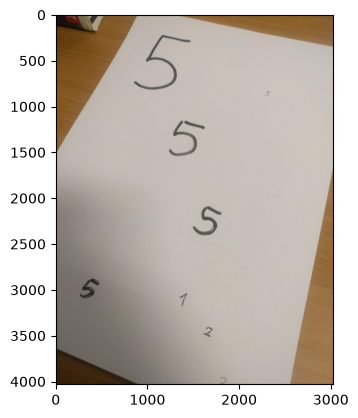

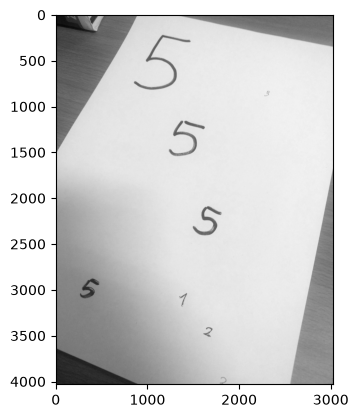

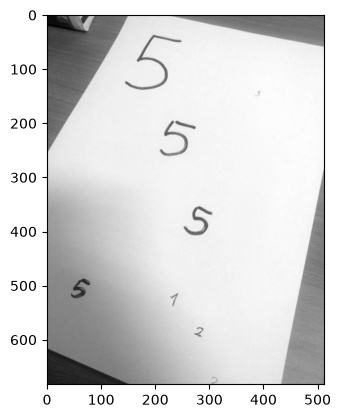

In [2]:
# Choose random image from the directory:
image_dir_path = Path('images-v1')
image_file_paths = list(image_dir_path.glob('*.jpg'))
image_file_path = random.choice(image_file_paths)

# Load image:
plt.figure()
img = skimage.io.imread(image_file_path)
plt.imshow(img)
print(("Original:", type(img), img.shape, img.dtype, img.min(), img.max()))

# Convert to grayscale:
plt.figure()
img = img.mean(axis=-1).astype(np.uint8)
plt.imshow(img, cmap='gray')
print(("Gray:", type(img), img.shape, img.dtype, img.min(), img.max()))

# Resize image:
plt.figure()
img_width = 512
img = skimage.transform.resize(img, (img_width / img.shape[1] * img.shape[0], img_width))
img = skimage.img_as_ubyte(img)
plt.imshow(img, cmap='gray')
print(("Resized:", type(img), img.shape, img.dtype, img.min(), img.max()))

## Detect Edges and Lines

('Edges:', (683, 512), dtype('bool'), np.False_, np.True_)


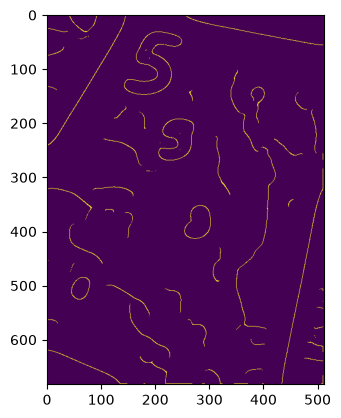

In [3]:
edge_sigmas = np.arange(15, 1, -1)

img_edges = None
hspace, angles, dists = None, None, None

for edge_sigma in edge_sigmas:
    img_edges = skimage.feature.canny(img, sigma=edge_sigma, low_threshold=0.15, high_threshold=0.35)

    hspace, angles, dists = skimage.transform.hough_line(img_edges)
    hspace, angles, dists = skimage.transform.hough_line_peaks(hspace, angles, dists, min_distance=25, min_angle=5)

    if angles.size == 4:
        break

plt.figure()
plt.imshow(img_edges)
print(("Edges:", img_edges.shape, img_edges.dtype, img_edges.min(), img_edges.max()))

## Convert Hough Lines to Points

In [4]:
def hough_to_points(angle, dist):
    x0, y0 = dist * np.cos(angle), dist * np.sin(angle)
    return (x0, y0), (x0 - np.sin(angle), y0 + np.cos(angle))   # two points on the line

# Convert found lines to points:
hough_points = np.array([hough_to_points(angle, dist) for angle, dist in zip(angles, dists)])
hough_points

array([[[ 1.13146084e+02,  6.79850259e+01],
        [ 1.12631046e+02,  6.88421932e+01]],

       [[ 7.82316881e+00, -4.02467145e+01],
        [ 8.80479599e+00, -4.00559055e+01]],

       [[ 5.44803087e+02,  1.05898992e+02],
        [ 5.44612278e+02,  1.06880620e+02]],

       [[-4.16992235e-14,  6.81000000e+02],
        [ 1.00000000e+00,  6.81000000e+02]]])

In [5]:
# Select max 4 longest lines:
# hough_line_lengths = np.array([np.linalg.norm(np.array(hough_point[0]) - np.array(hough_point[1])) for hough_point in hough_points])
# longest_hough_line_indexes = hough_line_lengths.argsort(descending=True)[:np.min([4, len(hough_line_lengths)])]
# hough_points = hough_points[longest_hough_line_indexes]
# hough_points

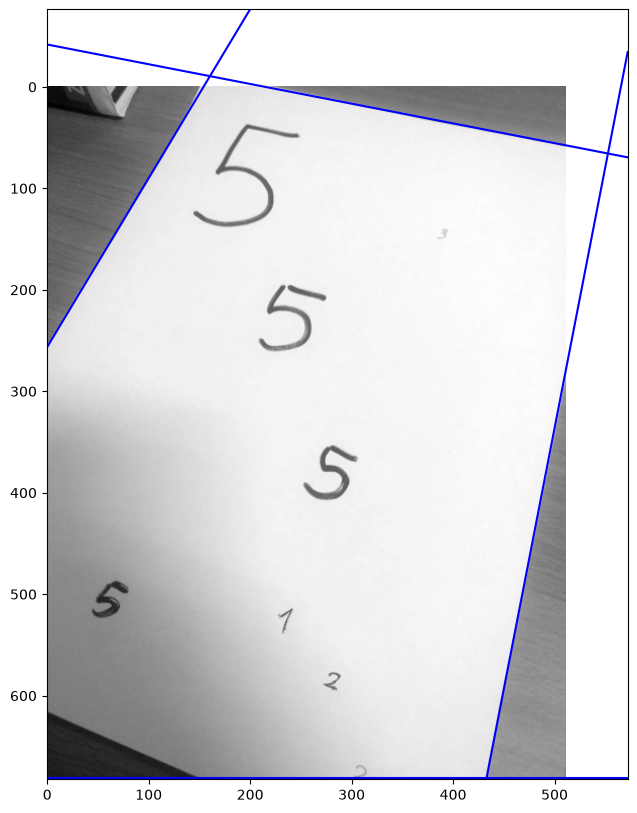

In [6]:
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(img,cmap="gray")

for p0, p1 in hough_points:
    ax.axline(p0, p1, color='b')

## Determine the candidate corners of the sheet

In [7]:
homogeneous_points = []
for hough_point in hough_points:
    pointA = np.concatenate((hough_point[0], np.ones(1)))
    pointB = np.concatenate((hough_point[1], np.ones(1)))
    homogeneous_points.append(np.cross(pointA, pointB))
homogeneous_points = np.array(homogeneous_points)

homogeneous_intersection_points = []
for i, _ in enumerate(homogeneous_points):
    before = homogeneous_points[0:i]
    after = homogeneous_points[(i+1):]
    others = np.concatenate([before, after])

    points = np.cross(homogeneous_points[i], others).tolist()
    homogeneous_intersection_points.extend(points)
homogeneous_intersection_points = np.array(homogeneous_intersection_points)
homogeneous_intersection_points

array([[-1.50691349e+02,  9.95707194e+00, -9.39692621e-01],
       [-2.60659344e+02,  3.46153064e+02, -3.42020143e-01],
       [ 2.18740929e+02, -5.83730932e+02, -8.57167301e-01],
       [ 1.50691349e+02, -9.95707194e+00,  9.39692621e-01],
       [ 5.52626256e+02,  6.56522779e+01,  1.00000000e+00],
       [-7.09488112e+02, -1.29940926e+02, -1.90808995e-01],
       [ 2.60659344e+02, -3.46153064e+02,  3.42020143e-01],
       [-5.52626256e+02, -6.56522779e+01, -1.00000000e+00],
       [-4.25059074e+02, -6.68488112e+02, -9.81627183e-01],
       [-2.18740929e+02,  5.83730932e+02,  8.57167301e-01],
       [ 7.09488112e+02,  1.29940926e+02,  1.90808995e-01],
       [ 4.25059074e+02,  6.68488112e+02,  9.81627183e-01]])

In [8]:
x = homogeneous_intersection_points[:, 0] / homogeneous_intersection_points[:, 2]
y = homogeneous_intersection_points[:, 1] / homogeneous_intersection_points[:, 2]
corner_point_candidates = np.unique(np.stack([x, y], axis=1), axis=0)
corner_point_candidates = corner_point_candidates[:, :2]
corner_point_candidates

array([[ -255.19047313,   681.        ],
       [  160.36238441,   -10.59609464],
       [  433.01477518,   681.        ],
       [  552.62625562,    65.65227791],
       [  762.11693747, -1012.0838507 ],
       [ 3718.31585051,   681.        ]])

## Determine the best 4 corners of the sheet by Geometric Transformation

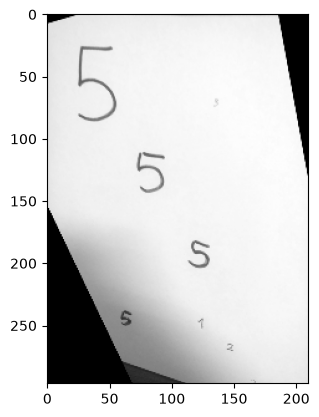

In [9]:
def sort_quadrilateral_points(points):
    points = np.asarray(points, dtype=float)
    c = points.mean(axis=0)
    points = points[np.argsort(np.arctan2(points[:, 1] - c[1], points[:, 0] - c[0]))]   # clockwise on screen
    return np.roll(points, -np.argmin(points.sum(axis=1)), axis=0)            # start at uppwer_left (smallest x + y)

# Assume 1mm per pixel for an A4 sheet (210x297mm):
sheet_width, sheet_height = 210, 297
sheet_up_left, sheet_up_right, sheet_low_left, sheet_low_right = [0, 0], [sheet_width, 0], [0, sheet_height], [sheet_width, sheet_height]
sheet_projection = sort_quadrilateral_points([sheet_up_left, sheet_up_right, sheet_low_right, sheet_low_left]) #list(permutations(sheet_points.values()))

img_transformed = None
img_transformed_light = 0

# Find best 4-point transformation:
for candidates in combinations(corner_point_candidates, 4):
    candidates = sort_quadrilateral_points(candidates)
    transform = skimage.transform.ProjectiveTransform.from_estimate(sheet_projection, candidates)

    if transform:
        img_t = skimage.transform.warp(img, transform, output_shape=(sheet_height,sheet_width))

        if np.isnan(img_t).any():
            continue

        # maximize the paper area (i.e. the light pixels):
        img_t_light = np.sum(img_t)

        if img_transformed_light <= img_t_light:
            img_transformed = img_t
            img_transformed_light = img_t_light

plt.imshow(img_transformed, cmap='gray')
plt.show()

## Binarize

(np.float64(-0.5989742673531281), np.float64(0.4717505092580965))

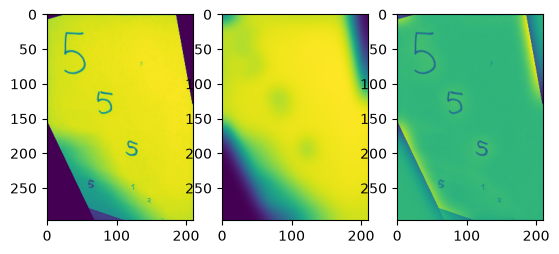

In [10]:
img_background = skimage.filters.threshold_local(img_transformed, block_size=65, offset=0.1)
img_preprocessed = img_transformed - img_background

ax = plt.figure().subplots(ncols=3)
ax[0].imshow(img_transformed)
ax[1].imshow(img_background)
ax[2].imshow(img_preprocessed)

img_preprocessed.min(), img_preprocessed.max()

dtype('bool')

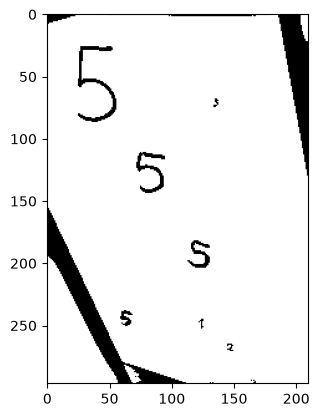

In [11]:
img_binarized = img_preprocessed > 0.05
plt.imshow(img_binarized, cmap='gray')
img_binarized.dtype

## Find Connected Components


10

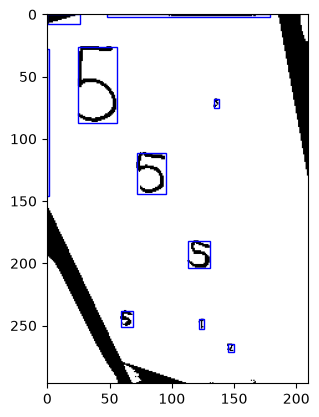

In [12]:
region_min_size, region_max_size = 5, 1000

labels = skimage.measure.label(img_binarized < 0.01)
regions = skimage.measure.regionprops(labels)
regions = [r for r in regions if region_min_size <= r.area <= region_max_size]

fig, ax = plt.subplots()
ax.imshow(img_binarized, cmap="gray")
for r in regions:
    (min_row, min_col, max_row, max_col) = r.bbox
    width = max_col - min_col
    height = max_row - min_row
    rect = patches.Rectangle((min_col,min_row),width,height, linewidth=1, edgecolor='b', facecolor='none')
    ax.add_patch(rect)
len(regions)

## Train ConvNet on MNIST dataset

### Prepare the data

In [13]:
# Model / data parameters
num_classes = 10
input_shape = (28, 28, 1)

# Load the data and split it between train and test sets
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Scale images to the [0, 1] range
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
# Make sure images have shape (28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")


# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

x_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


### Build the model

In [14]:
model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ]
)

model.summary()

E0000 00:00:1793665780.978348  990395 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_UNKNOWN: unknown error


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

### Load (or train) the model

In [15]:
weights_path = Path('model.weights.h5')

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

if weights_path.exists():
    model.load_weights(weights_path)
    print('Loaded weights')
else:
    batch_size = 128
    epochs = 15

    model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)
    model.save_weights(weights_path)
    print('Trained and saved weights')


Loaded weights


/home/beso/Development/ZHAW-Computer-Vision/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


### Evaluate the trained model

In [16]:
score = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 0.023120343685150146
Test accuracy: 0.9921000003814697


## Classify the detected numbers

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


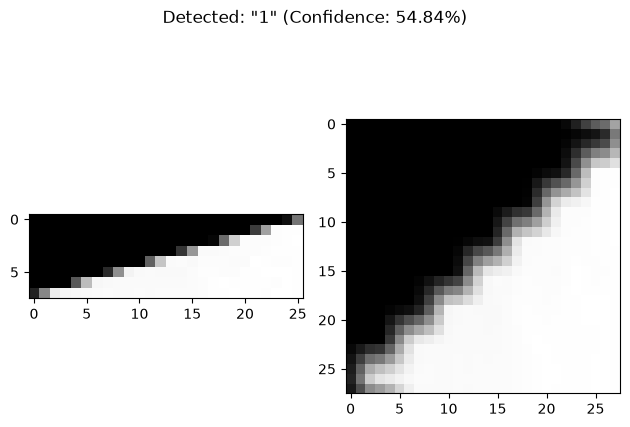

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


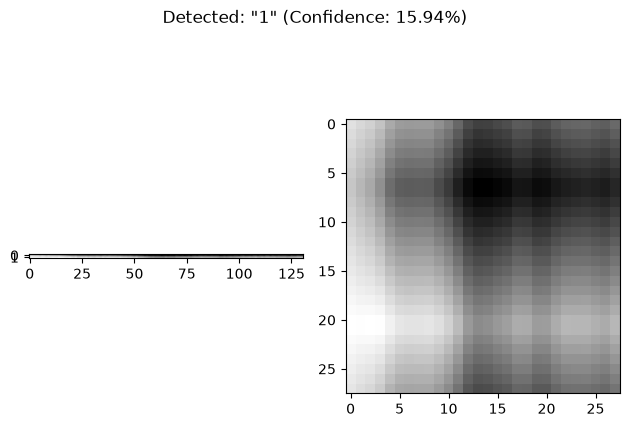

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


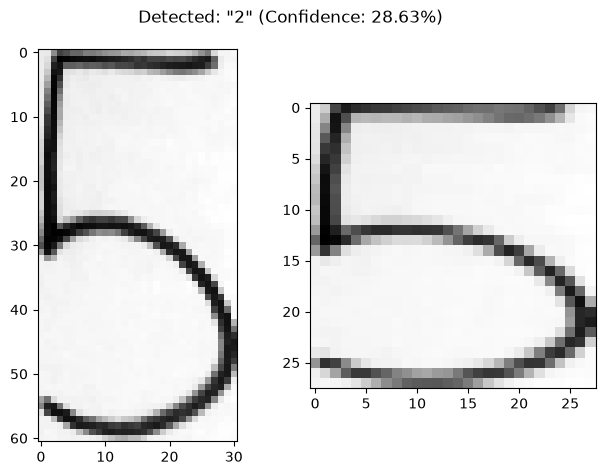

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


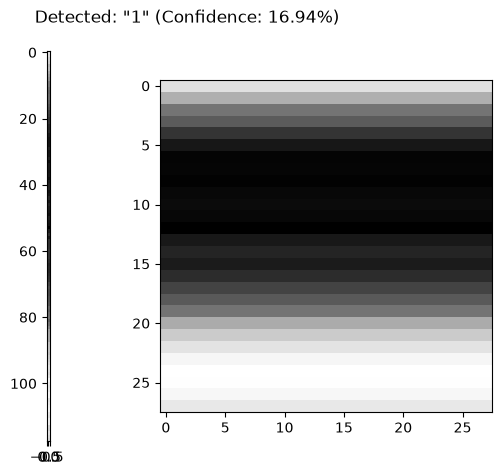

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


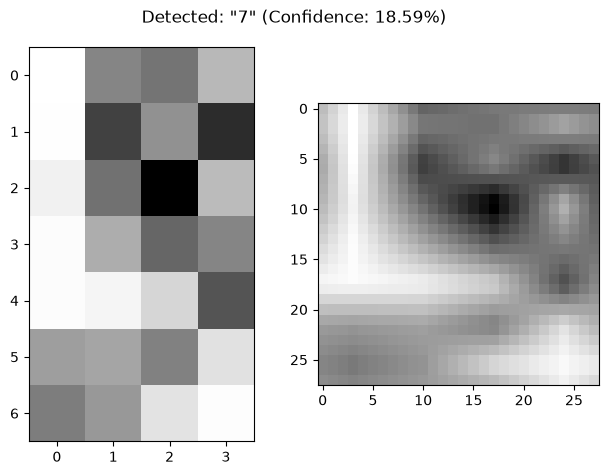

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


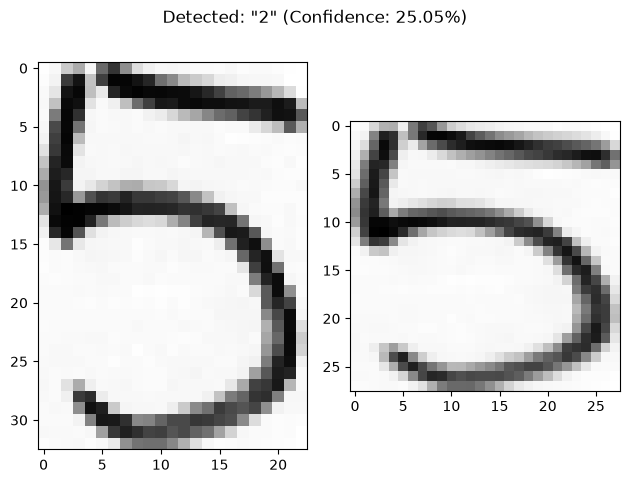

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


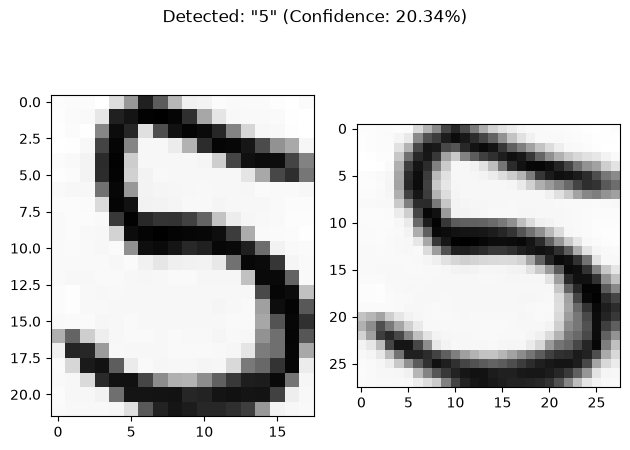

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


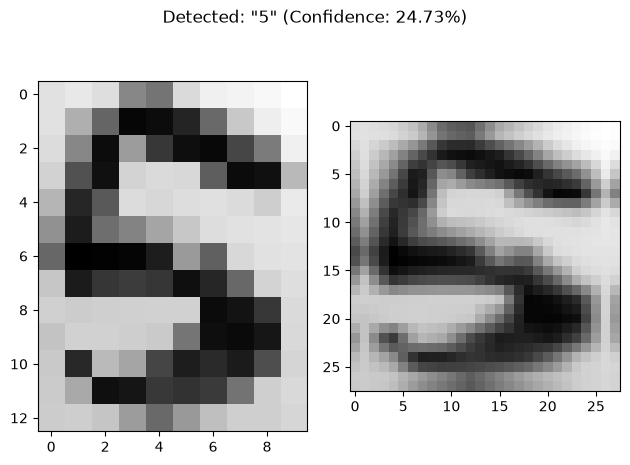

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


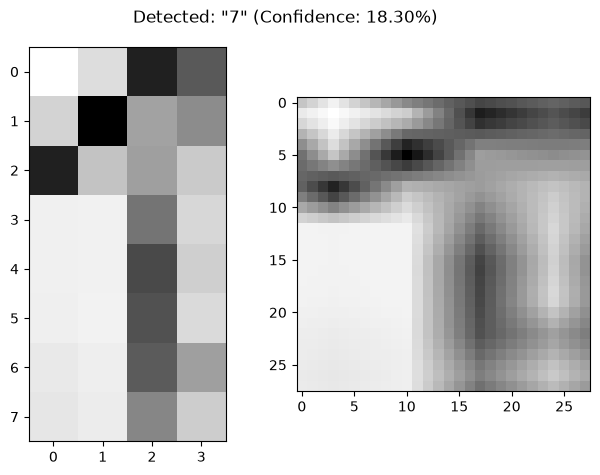

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


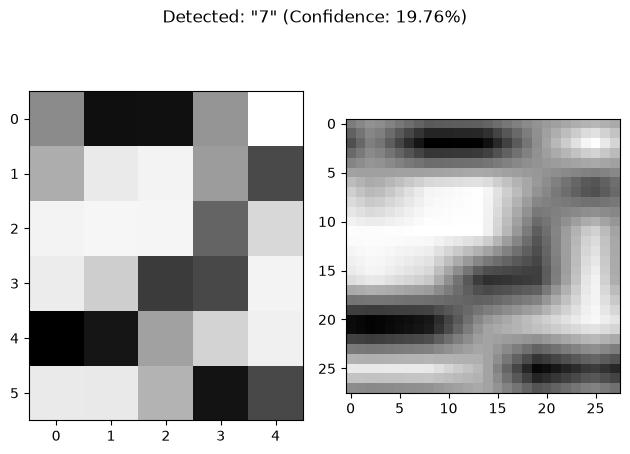

In [17]:
for r in regions:
    (min_row, min_col, max_row, max_col) = r.bbox
    img_number = img_transformed[min_row:max_row, min_col:max_col]

    img_resized = skimage.transform.resize(img_number, input_shape)
    p = model.predict(img_resized.reshape(1, input_shape[0], input_shape[1], input_shape[2]))

    fig, ax = plt.subplots(ncols=2)
    ax[0].imshow(img_number, cmap="gray")
    ax[1].imshow(img_resized, cmap="gray")
    fig.suptitle(f"Detected: \"{p.argmax()}\" (Confidence: {p.max() * 100:.2f}%)")
    fig.tight_layout()
    plt.show()